# 05 · Preprocessat i modelatge (versió corregida)

Projecte: segmentació de clients (K-means) i predicció de contractació de dipòsits (regressió logística).

## Correccions respecte a la versió anterior
1. **Índexs desalineats.** Els índexs de `X_train` es reiniciaven (`reset_index`) però els d'`y_train` no, de manera que `pd.concat([train8, y], axis=1)` creava files amb NaN. Això feia que les taxes de conversió per clúster (≈59-60 %) no fossin coherents amb la mitjana global (47,4 %). Ara tot conserva l'índex original i s'afegeix una comprovació (`assert`).
2. **K-means ajustat només amb *train*.** Abans es tornava a ajustar amb el conjunt de *test* (`kmeans.fit(test7)`), de manera que els clústers de test no eren comparables amb els de train, i el model desat era el d'un PCA de 2 components.
3. **Winsorització i escalat apresos només amb *train*.** Abans els límits IQR de `balance` es calculaven també amb el propi *test*.
4. **Mètriques de clustering sobre el model correcte.** La silueta de 0,5179 de les conclusions es calculava amb PCA sobre dades que ja incloïen la columna `cluster`; i la inèrcia de 13.556 era la del *test*. Aquí tot es calcula sobre *train* (i la silueta també sobre *test*).
5. **Regressió logística sense la columna `cluster`** (redundant: deriva de les mateixes variables) i **coeficients amb els noms reals** de les columnes (abans s'emparellaven amb `X.columns`, que són les variables originals, i quedaven mal etiquetats).
6. **Validació més completa:** validació creuada de 5 particions i comparació amb un model de referència (*baseline*).
7. **Segmentació redefinida (canvi metodològic, no només un error).** Amb les 12 variables, els clústers es separaven pel mes de contacte (`month_encoded`, de 0 a 11, sense estandarditzar) i la hipoteca, no pel perfil del client, i la conversió gairebé no variava (45,1 % vs 50,5 %). Ara es segmenta **només amb variables de perfil** (edat, saldo, estudis, estat civil, hipoteca, préstec), **totes estandarditzades**, sense el mes ni la campanya.
8. **Preprocessat compartit amb l'app** (`bank_utils.py`) i artefactes desats a `models/`, perquè l'app apliqui exactament les mateixes transformacions.

## 1. Importar les llibreries

In [1]:
import json
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, calinski_harabasz_score,
                             confusion_matrix, davies_bouldin_score, f1_score,
                             log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score

from bank_utils import (FEATURE_COLUMNS, MONTH_ORDER, RAW_COLUMNS, SEGMENT_COLUMNS,
                        apply_preprocessor, encode_features, fit_preprocessor,
                        fit_segmenter, segment_features)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 22
os.makedirs("models", exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Carregar el dataset

In [2]:
LOCAL = "datasets/bank_dataset_wins.csv"
URL = "https://raw.githubusercontent.com/Nicolakorff/BankMLProject/main/datasets/bank_dataset_wins.csv"
df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
df["age"] = df["age"].astype(int)
print(df.shape)
df.head()

(11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1033,1,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1033,1,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1033,1,-1.0,0.0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1.0,0.0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1.0,0.0,unknown,yes


## 3. Selecció de variables i divisió en *train* / *test*

Variables usades (9): `age`, `job`, `marital`, `education`, `balance`, `housing`, `loan`, `month`, `campaign`.
Variables descartades (7): `default`, `contact`, `day`, `duration`, `pdays`, `previous`, `poutcome`.

In [3]:
X = df[RAW_COLUMNS]
y = (df["deposit"] == "yes").astype(int)
print("Balanç de classes (%):")
print((y.value_counts(normalize=True) * 100).round(2).rename({0: "no", 1: "yes"}))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("\ntrain:", X_train.shape, "| test:", X_test.shape)
print("% yes train:", round(y_train.mean() * 100, 2), "| % yes test:", round(y_test.mean() * 100, 2))

Balanç de classes (%):
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64

train: (8929, 9) | test: (2233, 9)
% yes train: 47.38 | % yes test: 47.38


## 4. Codificació i preprocessat

Les transformacions viuen a `bank_utils.py` (les fa servir també l'app):
- `education` → ordinal (unknown=0, primary=1, secondary=2, tertiary=3); `month` → ordinal (jan=0 … dec=11).
- `job` → 5 grups (freelance, qualified, semi-qualified, no qualified, other) codificats numèricament.
- `housing`, `loan` → 0/1; `marital` → *one-hot*.
- `balance` → winsorització amb límits IQR **apresos amb train**; `age`, `balance`, `campaign` → `RobustScaler` **ajustat amb train**.

In [4]:
enc_train, enc_test = encode_features(X_train), encode_features(X_test)
prep = fit_preprocessor(enc_train)            # només train
P_train = apply_preprocessor(enc_train, prep)
P_test = apply_preprocessor(enc_test, prep)   # sense reajustar

assert (P_train.index == y_train.index).all() and (P_test.index == y_test.index).all()
assert not P_train.isna().any().any() and not P_test.isna().any().any()
print("Límits de winsorització de balance (train):", prep["balance_limits"])
P_train.describe().T[["mean", "std", "min", "max"]].round(2)

Límits de winsorització de balance (train): (-2224.0, 4032.0)


,mean,std,min,max
age,0.13,0.70,-1.24,3.29
balance,0.36,0.85,-1.77,2.23
campaign,0.12,0.76,-0.50,2.00
education_encoded,2.11,0.80,0.00,3.00
month_encoded,5.19,2.57,0.00,11.00
job_grouped_encoded,2.19,0.68,1.00,5.00
loan,0.13,0.34,0.00,1.00
housing,0.48,0.50,0.00,1.00
marital_divorced,0.11,0.32,0.00,1.00
marital_married,0.57,0.50,0.00,1.00


### 4.1 Variables per a la segmentació

K-means usa distàncies euclidianes, així que cada variable ha d'estar a una escala comparable. Es fan servir només variables que **descriuen el client**: `age`, `balance`, `education_encoded`, `housing`, `loan` i `marital` (one-hot). Queden fora `month` i `campaign` (descriuen el contacte) i `job` (el codi numèric és arbitrari i, en *one-hot*, fa els clústers inestables entre llavors). Tot s'estandarditza amb un `StandardScaler` ajustat amb *train*.

In [5]:
segmenter = fit_segmenter(P_train)
S_train = segment_features(P_train, segmenter)
S_test = segment_features(P_test, segmenter)
print("Variables de segmentació:", SEGMENT_COLUMNS)
S_train.describe().T[["mean", "std"]].round(2)

Variables de segmentació: ['age', 'balance', 'education_encoded', 'housing', 'loan', 'marital_divorced', 'marital_married', 'marital_single']


,mean,std
age,0.0,1.0
balance,0.0,1.0
education_encoded,0.0,1.0
housing,-0.0,1.0
loan,-0.0,1.0
marital_divorced,0.0,1.0
marital_married,0.0,1.0
marital_single,-0.0,1.0


## 5.1 K-means: selecció del nombre de clústers (només amb *train*)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,54304.300,0.268,1.474,2815.596
3,42375.848,0.341,1.243,3060.177
4,36344.960,0.359,1.208,2872.034
5,31523.043,0.317,1.228,2824.502
6,28769.427,0.314,1.180,2646.407
7,26568.708,0.302,1.310,2510.929
8,24265.515,0.311,1.153,2477.194
9,22380.342,0.332,1.135,2443.780


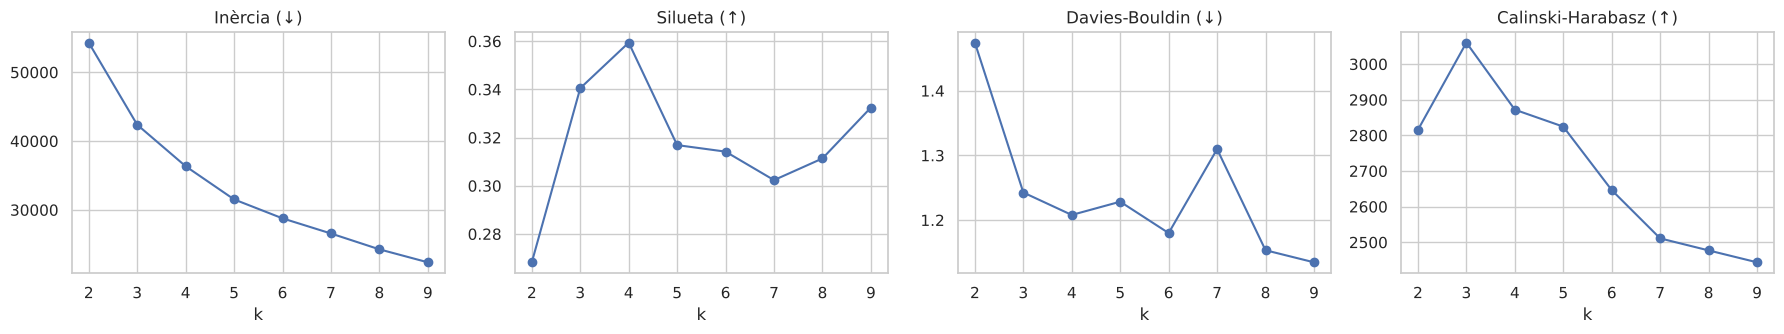

In [6]:
rows = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(S_train)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(S_train, km.labels_),
                 "davies_bouldin": davies_bouldin_score(S_train, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(S_train, km.labels_)})
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (col, title) in zip(axes, [("inertia", "Inèrcia (↓)"), ("silhouette", "Silueta (↑)"),
                                   ("davies_bouldin", "Davies-Bouldin (↓)"),
                                   ("calinski_harabasz", "Calinski-Harabasz (↑)")]):
    ax.plot(k_table.index, k_table[col], marker="o")
    ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

Criteri: silueta més alta, Davies-Bouldin baix i Calinski-Harabasz alt (la inèrcia baixa sempre en augmentar k, per això no es fa servir sola). **k = 4** té la silueta més alta; k = 3 és molt proper en les altres mètriques. Es tria k = 4 perquè a més separa millor els clients en conversió (es veu a la secció 8).

## 5.2 K-means final (ajustat només amb *train*)

In [7]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=0, n_init=10).fit(S_train)
train_clusters = kmeans.labels_
test_clusters = kmeans.predict(S_test)       # el MATEIX model; no es reajusta amb test

print("Train → Inèrcia:", round(kmeans.inertia_, 1),
      "| Silueta:", round(silhouette_score(S_train, train_clusters), 3),
      "| Davies-Bouldin:", round(davies_bouldin_score(S_train, train_clusters), 3),
      "| Calinski-Harabasz:", round(calinski_harabasz_score(S_train, train_clusters), 1))
print("Test  → Silueta:", round(silhouette_score(S_test, test_clusters), 3),
      "| Davies-Bouldin:", round(davies_bouldin_score(S_test, test_clusters), 3))
print("Mida dels clústers (train):", np.bincount(train_clusters).tolist())

# Estabilitat: mateixos clústers amb altres llavors? (ARI = 1 → idèntics)
aris = [adjusted_rand_score(train_clusters, KMeans(K, random_state=s, n_init=10).fit(S_train).labels_) for s in range(1, 6)]
print("ARI amb 5 llavors diferents (mínim):", round(min(aris), 3))

Train → Inèrcia: 36345.0 | Silueta: 0.359 | Davies-Bouldin: 1.208 | Calinski-Harabasz: 2872.0
Test  → Silueta: 0.358 | Davies-Bouldin: 1.214
Mida dels clústers (train): [1022, 1004, 2545, 4358]


ARI amb 5 llavors diferents (mínim): 1.0


## 6. Regressió logística

In [8]:
logistic = LogisticRegression(random_state=0, max_iter=1000).fit(P_train, y_train)
proba = logistic.predict_proba(P_test)[:, 1]
pred = (proba >= 0.5).astype(int)

metrics = {
    "AUC": roc_auc_score(y_test, proba),
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "Log-loss": log_loss(y_test, proba),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_auc = cross_val_score(LogisticRegression(max_iter=1000), P_train, y_train, cv=cv, scoring="roc_auc")

baseline = DummyClassifier(strategy="prior").fit(P_train, y_train)
base_proba = baseline.predict_proba(P_test)[:, 1]

print(pd.Series(metrics).round(4).to_string())
print(f"\nAUC en validació creuada (5 particions, train): {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")
print(f"Baseline (sempre la classe majoritària): accuracy={accuracy_score(y_test, baseline.predict(P_test)):.3f}, AUC={roc_auc_score(y_test, base_proba):.3f}")
cm = confusion_matrix(y_test, pred)
print("\nMatriu de confusió [[TN FP] [FN TP]]:\n", cm)

AUC          0.6824
Accuracy     0.6462
Precision    0.6309
Recall       0.6106
F1           0.6206
Log-loss     0.6429

AUC en validació creuada (5 particions, train): 0.675 ± 0.005
Baseline (sempre la classe majoritària): accuracy=0.526, AUC=0.500

Matriu de confusió [[TN FP] [FN TP]]:
 [[797 378]
 [412 646]]


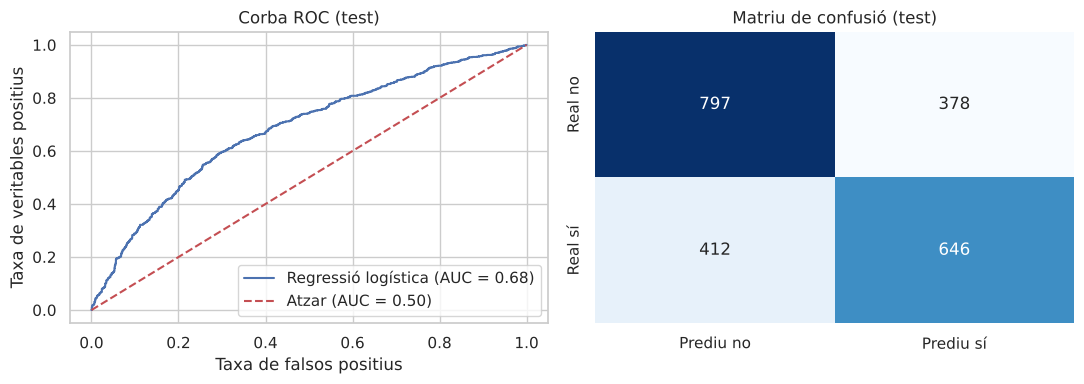

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_test, proba)
axes[0].plot(fpr, tpr, label=f"Regressió logística (AUC = {metrics['AUC']:.2f})")
axes[0].plot([0, 1], [0, 1], "r--", label="Atzar (AUC = 0.50)")
axes[0].set_xlabel("Taxa de falsos positius"); axes[0].set_ylabel("Taxa de veritables positius")
axes[0].set_title("Corba ROC (test)"); axes[0].legend()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Prediu no", "Prediu sí"], yticklabels=["Real no", "Real sí"])
axes[1].set_title("Matriu de confusió (test)")
plt.tight_layout(); plt.show()

## 7. Coeficients (amb els noms reals de les variables)

`age`, `balance` i `campaign` estan escalades amb `RobustScaler`; per això els coeficients de les variables numèriques i binàries no són directament comparables en magnitud, però el **signe** sí que és interpretable. `exp(coef)` és la *odds ratio*.

,coef,odds_ratio
housing,-0.720,0.487
loan,-0.414,0.661
campaign,-0.379,0.685
marital_married,-0.319,0.727
marital_divorced,-0.142,0.868
marital_unknown,0.000,1.000
month_encoded,0.008,1.008
marital_single,0.144,1.155
job_grouped_encoded,0.146,1.157
education_encoded,0.155,1.168


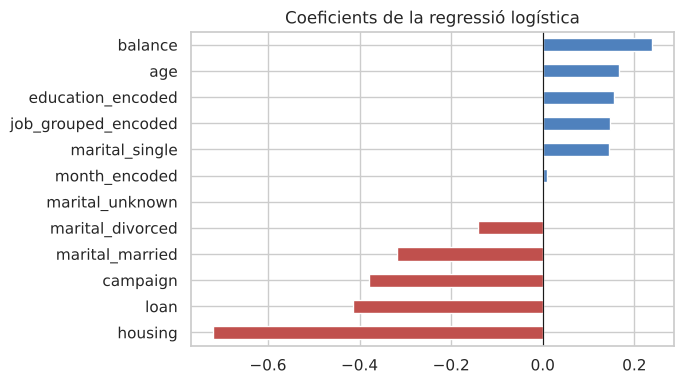

In [10]:
coefs = pd.DataFrame({"coef": logistic.coef_[0], "odds_ratio": np.exp(logistic.coef_[0])},
                     index=logistic.feature_names_in_).sort_values("coef")
display(coefs.round(3))
coefs["coef"].plot.barh(figsize=(7, 4), color=np.where(coefs["coef"] < 0, "#c0504d", "#4f81bd"))
plt.title("Coeficients de la regressió logística"); plt.axvline(0, color="k", lw=0.8); plt.tight_layout(); plt.show()

## 8. Anàlisi dels clústers (índexs alineats)

In [11]:
prof = pd.DataFrame({
    "n_clients": np.bincount(train_clusters),
    "edat_mitjana": enc_train["age"].groupby(train_clusters).mean(),
    "saldo_mitja_€": enc_train["balance"].groupby(train_clusters).mean(),
    "estudis (0-3)": enc_train["education_encoded"].groupby(train_clusters).mean(),
    "% casats": enc_train["marital_married"].groupby(train_clusters).mean() * 100,
    "% solters": enc_train["marital_single"].groupby(train_clusters).mean() * 100,
    "% divorciats": enc_train["marital_divorced"].groupby(train_clusters).mean() * 100,
    "% hipoteca": enc_train["housing"].groupby(train_clusters).mean() * 100,
    "% préstec": enc_train["loan"].groupby(train_clusters).mean() * 100,
    "campanya (mitjana)": enc_train["campaign"].groupby(train_clusters).mean(),
    "mes mitjà (0-11)": enc_train["month_encoded"].groupby(train_clusters).mean(),
    "conversió train %": y_train.groupby(train_clusters).mean() * 100,
    "conversió test %": y_test.groupby(test_clusters).mean() * 100,
    "prob. predita test %": pd.Series(proba).groupby(test_clusters).mean() * 100,
})
display(prof.round(1).T)
chi2_p = chi2_contingency(pd.crosstab(train_clusters, y_train.values))[1]
print(f"Conversió global: train {y_train.mean():.1%} | test {y_test.mean():.1%}")
print(f"Test chi-quadrat (clúster vs. dipòsit, train): p = {chi2_p:.2g}")

,0,1,2,3
n_clients,1022.0,1004.0,2545.0,4358.0
edat_mitjana,47.5,39.6,33.0,45.0
saldo_mitja_€,1009.7,672.5,1116.1,1226.4
estudis (0-3),2.1,2.1,2.3,2.0
% casats,0.0,72.4,0.0,100.0
% solters,0.0,27.4,99.9,0.0
% divorciats,100.0,0.0,0.0,0.0
% hipoteca,48.3,59.1,43.7,46.9
% préstec,16.0,100.0,0.0,0.0
campanya (mitjana),2.2,2.3,2.1,2.3


Conversió global: train 47.4% | test 47.4%
Test chi-quadrat (clúster vs. dipòsit, train): p = 8.1e-32


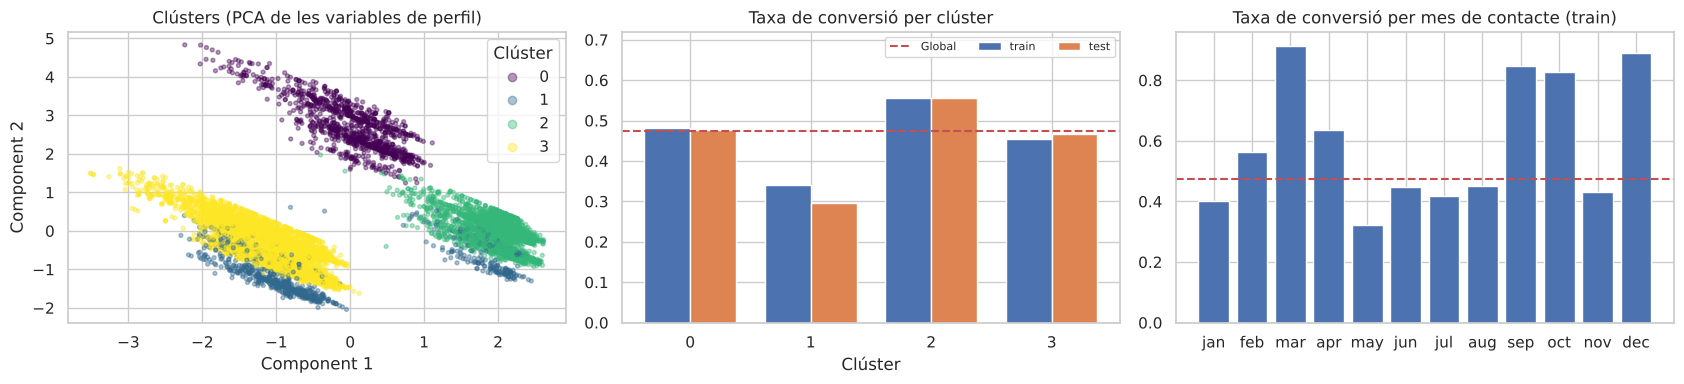

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
pca = PCA(n_components=2).fit(S_train)
Z = pca.transform(S_train)
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=train_clusters, cmap="viridis", alpha=0.4, s=8)
axes[0].set_title("Clústers (PCA de les variables de perfil)")
axes[0].set_xlabel("Component 1"); axes[0].set_ylabel("Component 2")
axes[0].legend(*sc.legend_elements(), title="Clúster")

conv = y_train.groupby(train_clusters).mean()
conv_t = y_test.groupby(test_clusters).mean()
x = np.arange(K); w = 0.38
axes[1].bar(x - w/2, conv.values, w, label="train"); axes[1].bar(x + w/2, conv_t.values, w, label="test")
axes[1].axhline(y_train.mean(), color="r", ls="--", label="Global")
axes[1].set_xticks(x); axes[1].set_xlabel("Clúster"); axes[1].set_title("Taxa de conversió per clúster"); axes[1].set_ylim(0, 0.72); axes[1].legend(loc="upper right", ncol=3, fontsize=8)

monthly = y_train.groupby(enc_train["month_encoded"]).mean()
axes[2].bar([MONTH_ORDER[int(m)] for m in monthly.index], monthly.values)
axes[2].axhline(y_train.mean(), color="r", ls="--")
axes[2].set_title("Taxa de conversió per mes de contacte (train)")
plt.tight_layout(); plt.show()

## 9. Guardar els artefactes

In [13]:
with open("models/preprocessor.pkl", "wb") as f: pickle.dump(prep, f)
with open("models/segmenter.pkl", "wb") as f: pickle.dump(segmenter, f)
with open("models/kmeans_model.pkl", "wb") as f: pickle.dump(kmeans, f)
with open("models/logistic_model.pkl", "wb") as f: pickle.dump(logistic, f)
with open("models/features.pkl", "wb") as f: pickle.dump(list(P_train.columns), f)

metadata = {"sklearn_version": sklearn.__version__, "k": K,
            "logistic_test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
            "logistic_cv_auc_mean": round(float(cv_auc.mean()), 4)}
with open("models/metadata.json", "w") as f: json.dump(metadata, f, indent=2)
# Perfil de cada clúster (l'app el mostra al costat de la predicció)
with open("models/cluster_profiles.json", "w") as f:
    json.dump({str(c): {k: round(float(v), 3) for k, v in row.items()} for c, row in prof.iterrows()}, f, indent=2)
print(json.dumps(metadata, indent=2))

{
  "sklearn_version": "1.9.1",
  "k": 4,
  "logistic_test_metrics": {
    "AUC": 0.6824,
    "Accuracy": 0.6462,
    "Precision": 0.6309,
    "Recall": 0.6106,
    "F1": 0.6206,
    "Log-loss": 0.6429
  },
  "logistic_cv_auc_mean": 0.6745
}


## 10. Prova addicional: `month` com a variable categòrica

El notebook mostra una estacionalitat molt marcada (la conversió canvia molt segons el mes), però el mes codificat com a nombre (0-11) només permet un efecte lineal, i el seu coeficient és gairebé zero. Aquesta prova el codifica amb *one-hot*. **No substitueix el model desat**; serveix per decidir la propera iteració.

In [14]:
def month_onehot(P, enc):
    out = P.drop(columns="month_encoded").copy()
    for i, m in enumerate(MONTH_ORDER):
        out[f"month_{m}"] = (enc["month_encoded"] == i).astype(float)
    return out

A, B = month_onehot(P_train, enc_train), month_onehot(P_test, enc_test)
m2 = LogisticRegression(max_iter=2000).fit(A, y_train)
p2 = m2.predict_proba(B)[:, 1]
print(f"Month com a nombre (model desat): AUC={metrics['AUC']:.3f}, accuracy={metrics['Accuracy']:.3f}, F1={metrics['F1']:.3f}")
print(f"Month one-hot:                    AUC={roc_auc_score(y_test, p2):.3f}, accuracy={accuracy_score(y_test, p2 >= .5):.3f}, F1={f1_score(y_test, p2 >= .5):.3f}")

Month com a nombre (model desat): AUC=0.682, accuracy=0.646, F1=0.621
Month one-hot:                    AUC=0.711, accuracy=0.666, F1=0.616


## 11. Conclusions

### Predicció (regressió logística)
- **AUC = 0,682** en *test* i **0,675 ± 0,005** en validació creuada: millor que l'atzar i que el model de referència (AUC 0,50; accuracy 52,6 %), però modest. Accuracy 64,6 %, precisió 63,1 %, recall 61,1 %, F1 0,621, log-loss 0,643.
- Matriu de confusió: 378 falsos positius i 412 falsos negatius. El model serveix per **prioritzar contactes**, no per decidir automàticament.
- Signe dels coeficients: tenir hipoteca (`housing`, odds ratio 0,49), préstec personal (`loan`), més contactes a la campanya (`campaign`) i estar casat/da **redueixen** la probabilitat de contractar; el saldo, l'edat, el nivell d'estudis i una feina qualificada l'**augmenten**.
- `month` codificat com a nombre no aporta res (coeficient ≈ 0), però codificat com a categoria (secció 10) l'AUC puja a **0,711**: és la millora més clara per a la propera iteració.

### Segmentació (K-means, k = 4, variables de perfil estandarditzades)
- Silueta 0,359 en *train* i 0,358 en *test*, Davies-Bouldin 1,208 i Calinski-Harabasz 2.872. Estructura de clústers feble-moderada però **estable**: amb 5 llavors diferents els clústers són idèntics (ARI = 1) i es mantenen en *test*.
- Perfils (conversió en *train* / *test*):
  - **Clúster 2** (2.545 clients): solters (99,9 %), els més joves (33 anys), sense préstec personal. **Conversió 55,6 % / 55,6 %**, la més alta.
  - **Clúster 0** (1.022): divorciats, 47 anys de mitjana. Conversió 48,1 % / 47,6 %.
  - **Clúster 3** (4.358): casats sense préstec personal, 45 anys, el saldo mitjà més alt (1.226 €). Conversió 45,5 % / 46,8 %.
  - **Clúster 1** (1.004): tots tenen préstec personal, majoritàriament casats (72 %), el saldo mitjà més baix (672 €). **Conversió 34,1 % / 29,7 %**, la més baixa.
- La diferència de conversió entre clústers és estadísticament significativa (chi-quadrat, p ≈ 8·10⁻³²) i les probabilitats que prediu la regressió logística per a cada clúster són coherents amb les reals (secció 8). El mes mitjà de contacte és gairebé igual a tots (≈ 5), de manera que ja no domina la segmentació.
- Els clústers estan definits sobretot per l'**estat civil** i el **préstec personal**, que també són variables del model de predicció: la segmentació aporta una lectura descriptiva per a màrqueting, no capacitat predictiva addicional.

### Limitacions i properes passes
- Codificar `month` com a categoria (o amb una codificació cíclica) al model de predicció.
- Es va triar k = 4 amb les mètriques de clustering (silueta més alta) i es va comprovar a més que separa bé la conversió; k = 3 és una alternativa gairebé equivalent.
- `job` no entra a la segmentació (el codi numèric és arbitrari i, en *one-hot*, els clústers deixen de ser estables). Convé revisar-ne l'agrupació (`retired` i `blue-collar` van com a «qualified»).
- Segmentar per estat civil exigeix cautela ètica: convé auditar que no genera tractaments discriminatoris abans de qualsevol ús real.
- `bank_dataset_wins.csv` ve de l'EDA, on s'imputen nuls (l'edat amb la mitjana de tot el dataset) i es winsoritza **abans** de dividir en train/test: hi ha una fuita lleu que aquí no es corregeix (només `balance` es torna a winsoritzar amb límits de train).
- Un sol *split* més validació creuada; no s'han provat altres models ni s'han ajustat hiperparàmetres.